In [10]:
from pathlib import Path
import sys, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.model_selection import StratifiedKFold

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists(): PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").exists(), "Run from project root or notebooks/"
sys.path.insert(0, str(PROJECT_ROOT))
from src.features import add_features
from src.split import time_based_split, create_stratified_kfold

DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = DATA_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
config = json.loads((ARTIFACT_DIR / "final_model_config.json").read_text(encoding="utf-8"))
FEATURE_COLS = config["feature_columns"]
CAT_COLS = config["categorical_columns"]
SELECTED = config["selected_model"]
print("Selected Model:", SELECTED, "| Features:", len(FEATURE_COLS), "| CV:", config.get("cv_strategy", "stratified"))


Selected Model: Weighted Blending | Features: 31 | CV: stratified


In [11]:
# Load the cache when compatible; rebuild it from CSV if it was pickled by an older pandas version.
feat_path = DATA_DIR / "train_featured.pkl"
all_df = None
if feat_path.exists():
    try:
        all_df = pd.read_pickle(feat_path)
        print("Loaded compatible cache: train_featured.pkl")
    except (NotImplementedError, ValueError, EOFError, pickle.UnpicklingError) as exc:
        print(f"Cache incompatible ({type(exc).__name__}); rebuilding from train.csv")

if all_df is None:
    raw = pd.read_csv(DATA_DIR / "train.csv")
    all_df = add_features(raw.drop(columns="is_fraud"))
    all_df["is_fraud"] = raw["is_fraud"].astype(int).to_numpy()
    all_df["id"] = raw["id"].to_numpy()

# 1. Gán Stratified 5-Fold trên toàn bộ dữ liệu train để phục vụ OOF Evaluation
all_df = create_stratified_kfold(all_df, target_col="is_fraud", n_splits=5, shuffle=True, random_state=42, fold_col="fold")

# 2. Vẫn duy trì tập Time-based holdout 15% để làm bài kiểm tra kiểm chứng độc lập (Sanity check)
splits = time_based_split(all_df, id_col="id", train_ratio=0.70, valid_ratio=0.15, buffer_size=0)
train_df, valid_df, holdout_df = splits["train"].sort_values("id").reset_index(drop=True), splits["valid"].sort_values("id").reset_index(drop=True), splits["test_holdout"].sort_values("id").reset_index(drop=True)
y_train, y_valid, y_holdout = [d["is_fraud"].to_numpy() for d in (train_df, valid_df, holdout_df)]

def align_categories(train_frame, other_frames):
    train_frame = train_frame.copy()
    others = [f.copy() for f in other_frames]
    for col in CAT_COLS:
        train_frame[col] = train_frame[col].astype("category")
        categories = train_frame[col].cat.categories
        for f in others: f[col] = pd.Categorical(f[col], categories=categories)
    return train_frame, others

X_train, (X_valid, X_holdout) = align_categories(train_df[FEATURE_COLS], [valid_df[FEATURE_COLS], holdout_df[FEATURE_COLS]])
print(f"Dữ liệu sẵn sàng! (Train: {len(X_train):,}, Valid: {len(X_valid):,}, Holdout: {len(X_holdout):,})")


Cache incompatible (NotImplementedError); rebuilding from train.csv
Dữ liệu sẵn sàng! (Train: 489,971, Valid: 104,995, Holdout: 104,994)


In [12]:
lgb_model = lgb.LGBMClassifier(**config["lightgbm_params"])
xgb_model = xgb.XGBClassifier(**config["xgboost_params"])

# Fit on 70% train segment
if SELECTED in ("LightGBM", "Weighted Blending"): lgb_model.fit(X_train, y_train)
if SELECTED in ("XGBoost", "Weighted Blending"):  xgb_model.fit(X_train, y_train)

def selected_predict(X):
    if SELECTED == "LightGBM": return lgb_model.predict_proba(X)[:, 1]
    if SELECTED == "XGBoost":  return xgb_model.predict_proba(X)[:, 1]
    if SELECTED == "Weighted Blending":
        a = float(config["ensemble_weights"]["lightgbm"])
        return a * lgb_model.predict_proba(X)[:, 1] + (1 - a) * xgb_model.predict_proba(X)[:, 1]
    raise ValueError(f"Unknown selected_model: {SELECTED}")

p_valid = selected_predict(X_valid)
p_holdout = selected_predict(X_holdout)
print(f"Validation AP: {average_precision_score(y_valid, p_valid):.6f} | Holdout AP: {average_precision_score(y_holdout, p_holdout):.6f}")


Validation AP: 0.341321 | Holdout AP: 0.364028


In [13]:
# Choose operating threshold using validation ONLY, for a target precision.
TARGET_PRECISION = 0.80
p, r, t = precision_recall_curve(y_valid, p_valid)
# p and r have length len(t)+1; last point has no threshold.
idx = np.flatnonzero((p[:-1] >= TARGET_PRECISION) & (r[:-1] > 0))
if len(idx):
    best_i = idx[np.argmax(r[idx])]
    threshold = float(t[best_i])
    print(f"Validation threshold for precision >= {TARGET_PRECISION:.0%}: {threshold:.6f}; recall={r[best_i]:.4f}")
else:
    threshold = 0.5
    print("No nontrivial validation threshold reaches target precision; using 0.5 as illustrative fallback.")
# Save chosen threshold as reporting metadata, not as a new hyperparameter tuned on holdout.

Validation threshold for precision >= 80%: 0.713931; recall=0.0828


In [14]:
def metric_row(name, y, probabilities, threshold):
    prediction = (probabilities >= threshold).astype(int)
    return {"dataset": name,
            "PR-AUC (AP)": average_precision_score(y, probabilities),
            "ROC-AUC": roc_auc_score(y, probabilities),
            "Brier": brier_score_loss(y, probabilities),
            "Precision@threshold": precision_score(y, prediction, zero_division=0),
            "Recall@threshold": recall_score(y, prediction, zero_division=0),
            "F1@threshold": f1_score(y, prediction, zero_division=0),
            "predicted_fraud_rate": prediction.mean()}
report = pd.DataFrame([metric_row("validation", y_valid, p_valid, threshold),
                       metric_row("holdout", y_holdout, p_holdout, threshold)])
display(report.round(6))
report.to_csv(ARTIFACT_DIR / "07_final_evaluation_metrics.csv", index=False)
print("Confusion matrix (holdout):\n", confusion_matrix(y_holdout, p_holdout >= threshold))
print(classification_report(y_holdout, p_holdout >= threshold, digits=4, zero_division=0))

,dataset,PR-AUC (AP),ROC-AUC,Brier,Precision@threshold,Recall@threshold,F1@threshold,predicted_fraud_rate
0,validation,0.341321,0.912565,0.013043,0.803371,0.082803,0.150131,0.001695
1,holdout,0.364028,0.919254,0.012733,0.796296,0.100000,0.177686,0.002057


Confusion matrix (holdout):
 [[103230     44]
 [  1548    172]]
              precision    recall  f1-score   support

           0     0.9852    0.9996    0.9923    103274
           1     0.7963    0.1000    0.1777      1720

    accuracy                         0.9848    104994
   macro avg     0.8908    0.5498    0.5850    104994
weighted avg     0.9821    0.9848    0.9790    104994



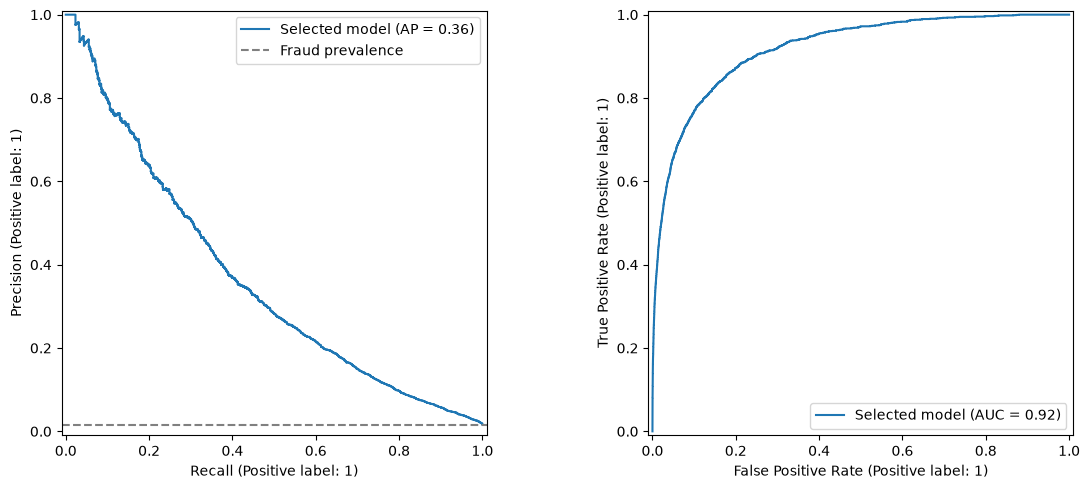

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
PrecisionRecallDisplay.from_predictions(y_holdout, p_holdout, ax=axes[0], name="Selected model")
axes[0].axhline(y_holdout.mean(), ls="--", color="grey", label="Fraud prevalence")
axes[0].legend()
RocCurveDisplay.from_predictions(y_holdout, p_holdout, ax=axes[1], name="Selected model")
plt.tight_layout()
plt.show()
# Diagnostic only: never re-select model, weight, features, or threshold using these plots.

In [16]:
holdout_errors = holdout_df[["id", "is_fraud"]].copy()
holdout_errors["fraud_probability"] = p_holdout
holdout_errors["predicted_fraud"] = (p_holdout >= threshold).astype(int)
holdout_errors["error_type"] = np.select(
    [(holdout_errors.is_fraud.eq(1) & holdout_errors.predicted_fraud.eq(0)),
     (holdout_errors.is_fraud.eq(0) & holdout_errors.predicted_fraud.eq(1))],
    ["False negative", "False positive"], default="Correct")
print(holdout_errors["error_type"].value_counts())
display(holdout_errors.sort_values("fraud_probability", ascending=False).head(10))
# Keep this error-analysis CSV private if IDs are sensitive.
holdout_errors.to_csv(ARTIFACT_DIR / "07_holdout_predictions.csv", index=False)
(ARTIFACT_DIR / "07_evaluation_metadata.json").write_text(
    json.dumps({"selected_model": SELECTED, "target_precision": TARGET_PRECISION,
                "validation_chosen_threshold": threshold, "holdout_pr_auc": float(average_precision_score(y_holdout, p_holdout)),
                "holdout_has_been_used_in_earlier_experiments": True}, indent=2), encoding="utf-8")

error_type
Correct           103402
False negative      1548
False positive        44
Name: count, dtype: int64


,id,is_fraud,fraud_probability,predicted_fraud,error_type
45773,640739,1,0.990585,1,Correct
86474,681440,1,0.984806,1,Correct
74283,669249,1,0.983691,1,Correct
32132,627098,1,0.978516,1,Correct
167,595133,1,0.971427,1,Correct
96402,691368,1,0.968891,1,Correct
10594,605560,1,0.967121,1,Correct
4847,599813,1,0.962843,1,Correct
48335,643301,1,0.961111,1,Correct
5241,600207,1,0.959746,1,Correct


219